# 03 - Synthetic channels and validation
Generates a few channels and reads the validation tables written by `scripts/validate_model.py` (run it first).

In [1]:
import sys, pathlib
ROOT = pathlib.Path.cwd().resolve().parent if pathlib.Path.cwd().name == 'notebooks' else pathlib.Path.cwd()
sys.path.insert(0, str(ROOT / 'src'))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from channel_model import *
P = load_channel_parameters()

7 of 13 clusters observable; {'delay_spread_m': 4.7188701098424195, 'delay_spread_sum_m': 4.008783678826101, 'doa_spread': 0.21650240215738853, 'dod_spread': 0.24462777876847513, 'pg_omni_db': -98.3365060448146, 'pg_maxdir_db': -98.4067692772351, 'n_taps': 242}


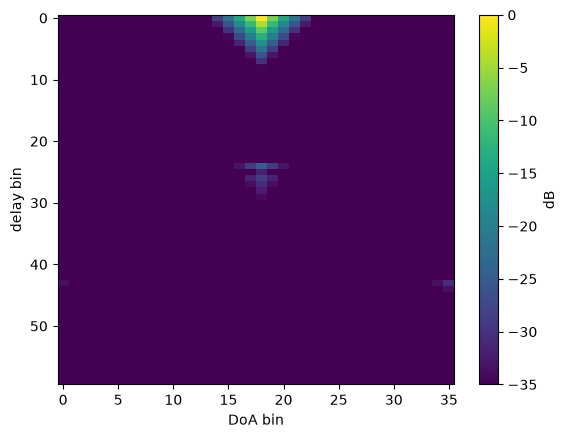

In [2]:
gen = ChannelGenerator(P, correction=DiscretizationCorrection.load(ROOT / 'data/processed/discretization_correction.npz'))
r = gen.generate(20.0, 'los', np.random.default_rng(1), keep_adps=True)
print(r.n_visible, 'of', r.clusters.n, 'clusters observable;', r.metrics)
plt.imshow(10*np.log10(np.maximum(r.adps.max(axis=2)[:60], 1e-30) / r.adps.max()), vmin=-35, vmax=0, aspect='auto')
plt.xlabel('DoA bin'); plt.ylabel('delay bin'); plt.colorbar(label='dB'); plt.show()

In [3]:
cvm = pd.read_csv(ROOT / 'results/tables/cvm_validation.csv')
cvm[['metric', 'condition', 'published_cvm', 'recomputed_paper_cvm', 'ours_vs_measured_cvm', 'null_cvm_95', 'status']]

,metric,condition,published_cvm,recomputed_paper_cvm,ours_vs_measured_cvm,null_cvm_95,status
0,delay,los,0.004,0.005692,0.015543,0.022967,consistent with measured (within sampling null...
1,doa,los,0.007,0.008901,0.034737,0.022828,deviates from measured beyond sampling noise
2,dod,los,0.003,0.004288,0.005300,0.021736,consistent with measured (within sampling null...
3,delay,nlos,0.007,0.004580,0.031043,0.025158,deviates from measured beyond sampling noise
4,doa,nlos,0.020,0.015300,0.089709,0.029029,deviates from measured beyond sampling noise
5,dod,nlos,0.029,0.022793,0.137410,0.027536,deviates from measured beyond sampling noise


In [4]:
pd.read_csv(ROOT / 'results/tables/pathloss_table2.csv')[['case', 'parameter', 'published_synthetic', 'ours_median_over_repeats', 'ours_p2.5', 'ours_p97.5']]

,case,parameter,published_synthetic,ours_median_over_repeats,ours_p2.5,ours_p97.5
0,los_omni,alpha,76.37,72.190,70.5400,74.600
1,los_omni,beta,1.80,1.955,1.8210,2.062
2,los_omni,sigma_ab,1.98,1.758,1.3900,2.108
3,los_omni,n_cim,1.86,1.747,1.7150,1.776
4,los_omni,sigma_cim,2.00,1.962,1.5940,2.332
5,los_maxdir,alpha,76.34,72.190,70.4100,74.430
6,los_maxdir,beta,1.82,1.968,1.8430,2.095
7,los_maxdir,sigma_ab,2.02,1.825,1.5120,2.210
8,los_maxdir,n_cim,1.88,1.766,1.7320,1.799
9,los_maxdir,sigma_cim,2.04,2.025,1.6570,2.400
